In [4]:
import numpy as np
from matplotlib import pyplot as plt
from IPython import display

from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern

import psutil, traceback, gc, atexit

import cv2
import tempfile, os, re

import requests
import json
import time
import random
import unicodedata
import pandas as pd
import base64
import mimetypes


In [5]:
#functions from the feature extraction pipeline
def normalize_text(text):
    # Normalize unicode characters, remove markdown formatting, lowercase, and strip dashes
    if not text:
        return text
    
    text = str(text)
    text = text.replace('*', '').replace('<<', '').replace('>>', '')
    text = re.sub(r'[-\u2010-\u2015\u2212\uFE58\uFE63\uFF0D]', '', text)
    normalized = unicodedata.normalize('NFKD', text)
    ascii_text = normalized.encode('ASCII', 'ignore').decode('ASCII')

    # Clean up whitespace + lowercase
    return ' '.join(ascii_text.split()).lower()

def send_prompt(
    system=None,
    prompt=None,
    image_url=None,             # if set, we download to a temp file and inline it
    image_path=None,            # local file path (sent as data URL)
    image_detail="auto",        
    seed=None,
    azure_api_key=os.getenv("AZURE_API_KEY"),
    azure_chat_url=None,        # built if not provided
    azure_model_name=os.getenv("AZURE_MODEL_NAME"),
    max_completion_tokens=1024,
    temperature=float(os.getenv("TEMPERATURE", "1.0")),
    top_p=float(os.getenv("TOP_P", "1.0")),
    frequency_penalty=float(os.getenv("FREQUENCY_PENALTY", "0.0")),
    presence_penalty=float(os.getenv("PRESENCE_PENALTY", "0.0")),
    max_time=int(os.getenv("MAX_TIME", "30"))
):

    # --- default azure_chat_url if not supplied ---
    if azure_chat_url is None:
        azure_endpoint_base = "https://aipolling.services.ai.azure.com/models"
        azure_api_version  = "2024-05-01-preview"
        azure_chat_url = f"{azure_endpoint_base}/chat/completions?api-version={azure_api_version}"

    # --- helpers ---
    def guess_mime_from_ext(path):
        """Guess MIME type from file extension, fallback to image/jpeg."""
        mime, _ = mimetypes.guess_type(path)
        return mime if mime else "image/jpeg"

    def image_to_data_url(path, mime=None):
        """Read file, encode as base64, return as data URL."""
        if not os.path.exists(path):
            raise FileNotFoundError(f"image_path not found: {path}")
        if mime is None:
            mime = guess_mime_from_ext(path)
        with open(path, "rb") as f:
            encoded = base64.b64encode(f.read()).decode("utf-8")
        return f"data:{mime};base64,{encoded}"

    tmp_path = None
    # If image_url is provided, download it
    if image_url:
        ext = os.path.splitext(image_url)[1].lower()
        suffix = ext if ext else ".bin"
        tmp_fd, tmp_path = tempfile.mkstemp(suffix=suffix)
        os.close(tmp_fd)  # we'll reopen with write
        resp_img = requests.get(image_url, timeout=max_time)
        if resp_img.status_code >= 400:
            raise RuntimeError(f"Failed to download image_url (HTTP {resp_img.status_code}): {image_url}")
        with open(tmp_path, "wb") as f:
            f.write(resp_img.content)
        image_path = tmp_path

    # --- build messages ---
    messages_list = []
    if system:
        messages_list.append({"role": "system", "content": system})

    user_content = [{"type": "text", "text": prompt}]

    if image_path:
        mime = guess_mime_from_ext(image_path)
        data_url = image_to_data_url(image_path, mime)
        user_content.append({
            "type": "image_url",
            "image_url": {"url": data_url, "detail": image_detail}
        })

    messages_list.append({"role": "user", "content": user_content})

    # --- body payload ---
    body = {
        "model": azure_model_name,
        "messages": messages_list,
        "temperature": float(temperature),
        "top_p": float(top_p),
        "frequency_penalty": float(frequency_penalty),
        "presence_penalty": float(presence_penalty),
        "max_completion_tokens": int(max_completion_tokens),
        "max_tokens": int(max_completion_tokens),  # compat
        "seed": int(seed) if seed is not None else None
    }

    # --- request ---
    headers = {
        "Content-Type": "application/json",
        "Accept": "application/json",
        "api-key": azure_api_key
    }

    resp = requests.post(
        azure_chat_url,
        headers=headers,
        json=body,
        timeout=max_time
    )

    raw_content = resp.text
    if resp.status_code != 200:
        raise RuntimeError(f"API request failed with status {resp.status_code}, body: {raw_content}")

    result = resp.json()

    # --- cleanup tmp file if used ---
    if tmp_path and os.path.exists(tmp_path):
        try:
            os.remove(tmp_path)
        except Exception:
            pass

    return result

# ------------------------------------------------------------
# 2. Load demographic categories from JSON
# ------------------------------------------------------------
with open("../generated_data/image_belief_features.json", "r", encoding="utf-8") as f:
    feature_data = json.load(f)

demo_features = feature_data["demo"]

# Normalize titles for the matching
for demo in demo_features:
    demo["title"] = normalize_text(demo["title"])

# ------------------------------------------------------------
# 3. Image prompt for demographic features
# ------------------------------------------------------------
image_prompt_template = """
I will show you a social media user's profile image.

Based SOLELY on this profile image, I will show you a number of demographic categories to which this user may belong to.
The categories are preceded by a title (e.g. "AGE:" or "SEX:" etc.) and a symbol (e.g. "A1", "A2" or "E1" etc.).
Please select, for each title, the most likely category to which this user belongs to BASED SOLELY ON THE VISUAL CONTENT OF THE PROFILE IMAGE.

In your answer present, for each title, the selected symbol.
Write out in full the category associated with the selected symbol.
The chosen symbol / category must be the most likely to accurately represent this user.
You must only select one symbol / category per title.
A title, symbol and category cannot appear more than once in your answer.

For each selected symbol / category, please note the level of Speculation involved in this selection.
Present the Speculation level for each selection on a scale from 0 (not speculative at all, clear visual evidence in the profile image) to 100 (fully speculative, no visual information related to this title in the profile image).
Speculation levels should be a direct measure of the amount of useful visual information available in the profile image.
Speculation levels pertain only to the visual information available in the profile image and should not be affected by additional information available to you from any other source.


To ensure consistency, use the following guidelines to determine speculation levels:

0-20 (Low speculation): The profile image provides clear and direct visual information relevant to the title (e.g., explicit visual evidence of age, gender presentation, etc.)
21-40 (Moderate-low speculation): The profile image provides indirect but strong visual indicators relevant to the title.
41-60 (Moderate speculation): The profile image provides some visual hints or partial information relevant to the title.
61-80 (Moderate-high speculation): The profile image provides limited and weak visual indicators relevant to the title.
81-100 (High speculation): The profile image provides no or almost no visual information relevant to the title.

For each selected category, please explain at length what visual features of the profile image contributed to your choice and your speculation level.

Preserve a strictly structured answer to ease parsing of the text.
Format your output as follows (this is just an example):

title: AGE
explanation: ...
symbol: A1)
category: 18-25
speculation: 90

For every title, you must include exactly these 5 fields: title, explanation, symbol, category, speculation. Do not omit any of them.
Please keep the EXACT WORDING for the titles!
YOU MUST GIVE AN ANSWER FOR EVERY TITLE!
"""

# ------------------------------------------------------------
# 4. Build dynamic image demographic prompt
# ------------------------------------------------------------
def build_image_demo_prompt(demo_features):
    
    # randomly shuffle the demographics to prevent position bias
    shuffled_demo = demo_features[:]
    random.shuffle(shuffled_demo)

    categories_text = "\n".join(
        [
            f"- **{demo['title']}:** \n    Choose one: [\n    " +
            ", \n    ".join([f"{key}) {val}" for key, val in demo["options"].items()]) +
            "]"
            for demo in shuffled_demo
        ]
    )

    return image_prompt_template + "\n\nBelow is the list of demographic categories to which this user may belong to:\n" + categories_text

# ----------------------------
# 5. Result Parsing Function
# ----------------------------

def parse_demo_response(response, demo_features, prefix="Image_Demo"):
    categories = {}
    explanations = {}
    speculations = {}
    symbols = {}

    for demo in demo_features:
        safe_key = re.sub(r"\W+", "_", demo["title"])
        if prefix:
            safe_key = f"{prefix}_{safe_key}"
        categories[f"{safe_key}_Category"] = None
        explanations[f"{safe_key}_Explanation"] = None
        symbols[f"{safe_key}_Symbol"] = None
        speculations[f"{safe_key}_Speculation"] = None

    demo_sections = re.split(r"(?=title:\s*)", str(response), flags=re.IGNORECASE)
    demo_sections = [section.strip() for section in demo_sections if section.strip() and not section.lower().startswith('below')]
    print(f"[DEBUG] Found {len(demo_sections)} sections to parse") 
    
    # Pattern for individual demographic
    pattern = (
        r"title:?\s*(.*?)\s*[\r\n]"
        r"explanation:?\s*(.*?)\s*[\r\n]"
        r"symbol:?\s*(.*?)\s*[\r\n]"
        r"category:?\s*(.*?)\s*[\r\n]"
        r"speculation:?\s*(\d+)\s*"
    )
    
    for i, section in enumerate(demo_sections):
        
        match = re.search(pattern, section, re.DOTALL | re.IGNORECASE)
        
        if match:
            title = normalize_text(match.group(1))
            explanation = normalize_text(match.group(2))
            symbol = normalize_text(match.group(3))
            category = normalize_text(match.group(4))
            speculation = normalize_text(match.group(5))
            
            matched_demo = None
            for d in demo_features:
                if d["title"] in title or title in d["title"]:
                    matched_demo = d
                    break
            if matched_demo:
                safe_key = re.sub(r"\W+", "_", matched_demo["title"])
                if prefix:
                    safe_key = f"{prefix}_{safe_key}"
                categories[f"{safe_key}_Category"] = category.strip()
                explanations[f"{safe_key}_Explanation"] = explanation.strip()
                symbols[f"{safe_key}_Symbol"] = symbol.strip()
                speculations[f"{safe_key}_Speculation"] = int(speculation.strip())

    return {**categories, **explanations, **speculations, **symbols}

# ------------------------------------------------------------
# 6. Build the request body for image inference using send_prompt
# ------------------------------------------------------------
def infer_image_demographics(image_url = None, image_path = None, model_name = None, demo_features = None):
    prompt = build_image_demo_prompt(demo_features)
    
    system_message = "You are a helpful assistant."

    try:
        result = send_prompt(
            system=system_message,
            prompt=prompt,
            image_url=image_url,
            image_path = image_path,
            azure_model_name=model_name,
            max_completion_tokens=16384,
            max_time=60
        )
        
        reply = result["choices"][0]["message"]["content"]
        return reply
        
    except Exception as e:
        print(f"Error in send_prompt: {e}")
        raise

# ------------------------------------------------------------
# 7. Secondary GPT cleanup function
# ------------------------------------------------------------
image_cleanup_prompt_template = """
You will be shown a long-form response to a question asking to assign a series of demographic categories to a user based solely on their profile image.
Your task is to extract and reformat the category assessments into a strict format.

CRITICAL FORMATTING RULES:
- Each demographic must be formatted EXACTLY as follows:
title: <FULL TITLE TEXT>
explanation: <FULL EXPLANATION TEXT>
symbol: <SYMBOL CODE>
category: <FULL CATEGORY TEXT>
speculation: <NUMERIC VALUE ONLY>

- Each field must be on its own separate line
- Preserve ALL original content from explanations, categories, and titles - do not summarize or shorten
- For speculation, use ONLY the numeric value (e.g., "50" not "fifty" or "50%")
- Remove any asterisks, markdown, or extra formatting from the original
- Ensure there is exactly one blank line between each complete demographic assessment
- If any field is missing, include the field name with nothing after it (e.g., "explanation:")

CHARACTER AND ENCODING RULES:
- Use only standard ASCII hyphens (-) for all dashes and hyphens in titles and categories
- Replace any special dashes (‑, –, —) with regular hyphens (-)
- Ensure all text uses standard ASCII characters only
- Remove any non-ASCII characters or convert them to their closest ASCII equivalent
- Use regular parentheses () not special parentheses

EXAMPLES OF CORRECT FORMATTING:

Example 1:
title: AGE
explanation: The profile image shows a person with visible wrinkles and gray hair...
symbol: A1)
category: 18-25
speculation: 50

Example 2:
title: SEX
explanation: The profile image presents masculine facial features and short haircut...
symbol: E1)
category: Male
speculation: 75

COMMON MISTAKES TO AVOID:
- WRONG: speculation: fifty (50)
- CORRECT: speculation: 50

- WRONG: symbol: E1) (with extra spaces)
- CORRECT: symbol: E1)

- WRONG: Using markdown like **title:**
- CORRECT: title:

- WRONG: Combining multiple fields on one line
- CORRECT: Each field on its own line

Now, clean and reformat the following response to match this exact structure. Preserve all original meaning but enforce the strict formatting and character rules:

{raw_output}
"""

def clean_image_output(raw_output, model_name):
    system_message = "You are a helpful assistant."
    
    try:
        result = send_prompt(
            system=system_message,
            prompt=image_cleanup_prompt_template.format(raw_output=raw_output),
            azure_model_name=model_name,
            max_completion_tokens=16384,
            max_time=60
        )
        
        reply = result["choices"][0]["message"]["content"]
        return reply
        
    except Exception as e:
        print(f"Error in cleanup send_prompt: {e}")
        raise

# ------------------------------------------------------------
# 8. GPT call with retry logic for image demographics
# ------------------------------------------------------------
def infer_image_demographics_with_retry(image_source, model_name, demo_features, prefix="Image_Demo", max_retries=5):
    parsed_result = {}
    response_text = None
    cleaned_text = None
    
    for attempt in range(1, max_retries + 1):
        try:
            if str(image_source).startswith("http"):
                response_text = infer_image_demographics(
                    image_url = image_source, 
                    model_name = model_name, 
                    demo_features=demo_features)
            else:
                response_text = infer_image_demographics(
                    image_path = image_source, 
                    model_name = model_name, 
                    demo_features=demo_features)
                
            parsed_result = parse_demo_response(response_text, demo_features, prefix=prefix)

            # if parsed result is incomplete, proceed with secondary cleanup
            if any(value is None for value in parsed_result.values()):
                print(f"[DEBUG] Parsing incomplete for image demographics → attempting cleanup.")
                cleaned_text = clean_image_output(response_text, model_name)
                parsed_result = parse_demo_response(cleaned_text, demo_features, prefix=prefix)

            # if still incomplete, raise exception to retry full GPT
            if any(value is None for value in parsed_result.values()):
                raise ValueError("Parsed result is empty. Retrying...")
            else:
                print(f"Image demographic parsing succeeded")
            return response_text, cleaned_text, parsed_result

        except Exception as e:
            print(f"Attempt {attempt}/{max_retries} failed for image demographics ({model_name}): {e}")
            if attempt < max_retries:
                time.sleep(2 ** attempt * 0.1)  
    
    return response_text, cleaned_text, parsed_result

In [6]:
# Create sampling grid (position, and blanking window size)
x,y,w,h = np.meshgrid(np.linspace(0,32,32),np.linspace(0,32,32),np.linspace(1,8,7),np.linspace(1,8,7))

X = np.vstack((x.ravel(),y.ravel(),w.ravel(),h.ravel())).T

# Storage for samples
Xm = []
fm_dict = {}

# First sample
state = X[np.random.randint(0,X.shape[0]),:].astype(int)
Xm.append(state)


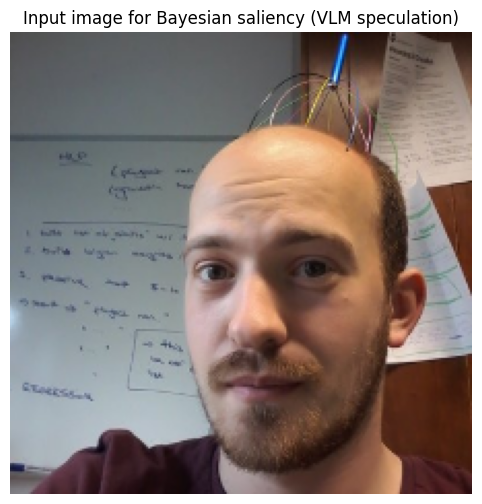

In [7]:
#load input
def load_image_from_url_or_path(image_source, input_size=None):
    if str(image_source).startswith("http"):
        resp = requests.get(image_source, timeout=30)
        img = cv2.imdecode(np.frombuffer(resp.content, np.uint8), cv2.IMREAD_COLOR)
    else:
        img = cv2.imread(image_source)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    if input_size is not None:
        img = cv2.resize(img, input_size)
    return img

image_path = "https://pbs.twimg.com/profile_images/776047601816829953/suLLGY-y_400x400.jpg"
img = load_image_from_url_or_path(image_path, input_size=(224, 224))
h, w = img.shape[:2]

plt.figure(figsize=(8, 6))
plt.imshow(img)
plt.axis("off")
plt.title("Input image for Bayesian saliency (VLM speculation)")
plt.show()


In [8]:
_, _, base_result = infer_image_demographics_with_retry(
    image_source=image_path,
    model_name= "Llama-4-Maverick-17B-128E-Instruct-FP8",
    demo_features=demo_features,
    prefix="Image_Demo",
)

# Build a dict of baseline speculation scores for all demographics
baseline_scores = {}
for demo in demo_features:
    key = f"Image_Demo_{demo['title'].replace(' ', '_')}_Speculation"
    baseline_scores[key] = base_result.get(key, np.nan)

# Initialize per-feature sample arrays
for key in baseline_scores.keys():
    fm_dict[key] = []

[DEBUG] Found 6 sections to parse
Image demographic parsing succeeded


In [9]:
h, w = img.shape[:2]
h, w = int(h), int(w)


In [10]:
# ===============================================================
# CREATE SAMPLING GRID WITH LARGER OCCLUSION WINDOWS
# ===============================================================
grid_pos = 32  # defines the grid density

xv, yv, wv, hv = np.meshgrid(
    np.linspace(0, grid_pos - 1, grid_pos),   # x positions
    np.linspace(0, grid_pos - 1, grid_pos),   # y positions
    np.linspace(4, 16, 9),                    # widths
    np.linspace(4, 16, 9),
    indexing="ij"
)

# the full set of candidate masks, every combination of position and size
X = np.vstack((xv.ravel(), yv.ravel(), wv.ravel(), hv.ravel())).T



In [ ]:
def run_saliency_for_feature(demo_feature, img, baseline_scores):
    """
    Run a full occlusion+GP saliency loop for one demographic feature.
    Uses smoothed multi-sample masking and amplified delta transformation
    to emphasize meaningful changes (e.g. ±10 speculation difference).
    """

    feature_name = demo_feature["title"].replace(" ", "_")
    feature_key = f"Image_Demo_{feature_name}_Speculation"

    L(f"\n=== Starting per-feature saliency loop for {feature_name} ===")

    fm_dict = {feature_key: []}
    raw_scores = []  # store masked speculation scores

    #initialize states
    state = X[np.random.randint(0, X.shape[0]), :].astype(float) #a randomly chosen mask
    Xm = [state]
    prev_state = None

    # Start from a random occlusion patch
    nx, ny, nw, nh = len(np.unique(xv)), len(np.unique(yv)), len(np.unique(wv)), len(np.unique(hv))
    h_img, w_img = img.shape[:2]
    # scales grid coordinates (0–32) to pixel coordinates in the actual image
    scale_x = w_img / grid_pos
    scale_y = h_img / grid_pos
    max_vals = np.array([xv.max(), yv.max(), wv.max(), hv.max()])

    for i in range(30):
        try:
            # --- 1. Apply occlusion mask ---
            x0, y0, ww, hh = [float(v) for v in np.ravel(state)]
            # Converts the sampled (x, y, w, h) from grid space → pixel space
            x0_px = int(round(x0 * scale_x))
            y0_px = int(round(y0 * scale_y))
            ww_px = int(round(ww * scale_x))
            hh_px = int(round(hh * scale_y))

            # guarantees that the mask does not extend outside the image boundaries
            x1 = max(x0_px - ww_px, 0)
            y1 = max(y0_px - hh_px, 0)
            x2 = min(x0_px + ww_px, w_img)
            y2 = min(y0_px + hh_px, h_img)

            masked_img = img.copy()
            masked_img[y1:y2, x1:x2, :] = 128 #Blanks out a rectangular region of the image with a gray patch (value 128) how?

            tmp_fd, tmp_path = tempfile.mkstemp(suffix=".jpg")
            os.close(tmp_fd)
            cv2.imwrite(tmp_path, cv2.cvtColor(masked_img, cv2.COLOR_RGB2BGR))

            # --- 2. Query VLM multiple times to compensate randomness ---
            n_repeat = 2
            masked_scores = []
            for _ in range(n_repeat):
                #Runs the model again on the masked image and collects the speculation scores
                _, _, masked_result = infer_image_demographics_with_retry(
                        image_source=tmp_path,
                        model_name="Llama-4-Maverick-17B-128E-Instruct-FP8",
                        demo_features=[demo_feature],
                        prefix="Image_Demo",
                    )
                ms = masked_result.get(feature_key)
                if ms is not None:
                    masked_scores.append(float(ms))

            try:
                os.remove(tmp_path)
            except:
                pass

            if len(masked_scores) == 0:
                continue
            # averaged speculation score from the two runs
            masked_score = np.mean(masked_scores)  
            raw_scores.append(masked_score)

            # --- 3. Compute amplified delta ---
            base_score = baseline_scores.get(feature_key)
            if base_score is None:
                continue

            delta_raw = masked_score - base_score
            p = 1.6   # power transform exponent
            delta_trans = np.sign(delta_raw) * (abs(delta_raw) ** p) # Small changes get suppressed, Large differences get exaggerated

            fm_dict[feature_key].append(float(delta_trans))

            # --- 4. Prepare GP data ---
            fm_mean = np.array(fm_dict[feature_key]) #gather all the recorded delta_trans values for this feature so far
            fm_mean = (fm_mean - fm_mean.mean()) / (fm_mean.std() + 1e-6) # z-score normalization of the delta_trans values

            Xm_arr = np.array(Xm) # an array of all the mask coordinates so far
            # normorlize the position inputs to 0-1
            X_norm = X / max_vals
            Xm_norm = Xm_arr / max_vals

            # --- 5. Fit GP ---
            gp = GaussianProcessRegressor(kernel=Matern(nu=1.5), alpha=0.05)
            gp.fit(Xm_norm, fm_mean)
            #mu(exploitation): how important each region likely is, given what we’ve seen, go where importance is high
            #sig(exploration): how unsure we are about that prediction, go where uncertainty is high
            mu, sig = gp.predict(X_norm, return_std=True) 

            # --- 6. Acquisition with exploration bias ---
            acq = mu + 2.5 * sig + 0.05 * (X[:, 2] + X[:, 3])  # stronger sig weight, encourages larger masks slightly

            # Add spatial exploration encouragement,so not repeatedly sample very similar masks
            if len(Xm) > 5:
                dist = np.min(np.linalg.norm(X[:, None, :] - np.array(Xm)[None, :, :], axis=-1), axis=1)
                acq += 0.1 * dist
            # if acquisition values are nearly identical, pick a random candidate to avoid stagnation
            acq_std = np.std(acq)
            if acq_std < 1e-3:
                aq_bin = np.random.randint(len(X))
            else:
                aq_bin = int(np.argmax(acq))

            # --- 7. Update next state ---
            prev_state = state.copy()
            state = X[aq_bin].astype(float)

            # Inject random jitter if stagnant
            if np.allclose(state, prev_state) or sig.std() < 0.05:
                jitter = np.random.randn(4) * [1.5, 1.5, 2.0, 2.0]
                state += jitter
                state = np.clip(
                    state,
                    [X[:, 0].min(), X[:, 1].min(), X[:, 2].min(), X[:, 3].min()],
                    [X[:, 0].max(), X[:, 1].max(), X[:, 2].max(), X[:, 3].max()],
                )
                L(f"[DEBUG] Forced exploration jitter Δ={np.round(jitter, 2)}")

            if i % 6 == 0 and i > 0:
                rand_state = X[np.random.randint(0, X.shape[0]), :].astype(float)
                L("[DEBUG] Periodic random exploration injected")
                state = rand_state

            Xm.append(state)

            # --- 8. Visualization ---
            if i % 1 == 0:
                ov = mu.reshape(nx, ny, nw, nh).mean(axis=(-1, -2))
                sxy = np.sum(sig.reshape(nx, ny, nw, nh), axis=(-1, -2))
                ov_img = cv2.resize(ov.T.astype(np.float32), (w_img, h_img), interpolation=cv2.INTER_LINEAR)

                fig, ax = plt.subplots(1, 3, figsize=(15, 5))
                ax[0].imshow(masked_img)
                ax[0].set_title(f"{feature_name} — masked (iter {i})")

                ax[1].imshow(img)
                ax[1].imshow(ov_img, alpha=0.5, cmap="jet")
                ax[1].set_title(f"{feature_name} — sensitivity")

                acq_img = cv2.resize((5 * sxy.T + ov.T).astype(np.float32), (w_img, h_img))
                ax[2].imshow(acq_img, cmap="jet")
                ax[2].set_title("Acquisition function")

                plt.tight_layout()
                display.clear_output(wait=True)
                display.display(plt.gcf())
                plt.pause(0.1)
                plt.close(fig)

        except Exception as e:
            L(f"{feature_name} ITER {i} exception:\n{traceback.format_exc()}")
            break

    # --- 9. Final debug summary ---
    print("\n--- FINAL DEBUG SUMMARY ---")
    print("Xm sample ranges (first 10):\n", np.array(Xm[:10]))
    print("fm_dict lengths per feature:")
    for k, v in fm_dict.items():
        print(k, len(v), " mean:", np.mean(v))
    print("mu mean/std:", mu.mean(), mu.std())
    print("sig mean/std:", sig.mean(), sig.std())
    print("masked speculation mean/std:", np.mean(raw_scores), np.std(raw_scores))

    arr = np.array(fm_dict[feature_key])
    L(f"{feature_name:60s} len={len(arr):3d} mean={arr.mean():.6f} std={arr.std():.6f}")


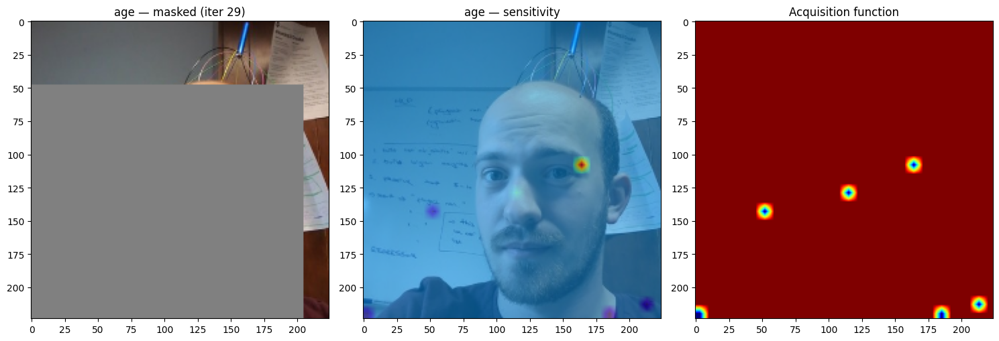

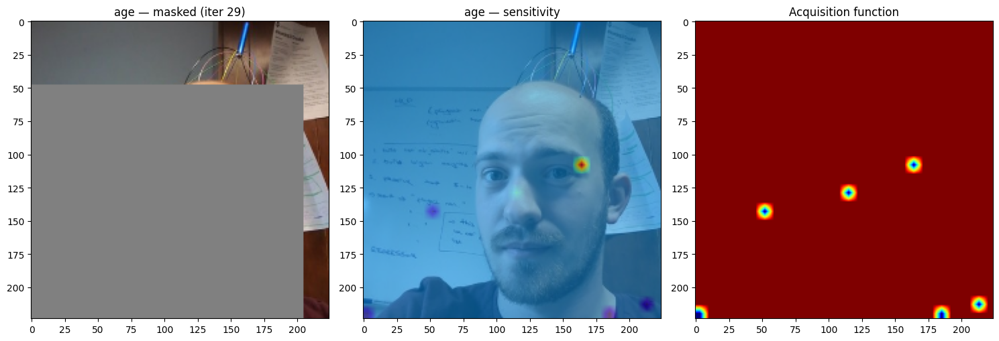


--- FINAL DEBUG SUMMARY ---
Xm sample ranges (first 10):
 [[23.         15.         14.5        16.        ]
 [ 0.         31.         16.         16.        ]
 [26.42097817 12.57540008 16.         16.        ]
 [ 0.40550122  1.68924683 13.17197743 15.21440472]
 [ 1.57783062  0.22725083 16.         16.        ]
 [ 1.01615076  0.         16.         16.        ]
 [30.06854499 29.58689511 15.25808217 16.        ]
 [30.         30.          8.5         7.        ]
 [ 7.4773005  16.66556933 16.         14.2508126 ]
 [18.81406764  0.         16.         15.05381551]]
fm_dict lengths per feature:
Image_Demo_age_Speculation 30  mean: 36.0790367472448
mu mean/std: -6.085490818837128e-06 0.008334061049163016
sig mean/std: 0.9999434474746987 0.006648951372536045
masked speculation mean/std: 52.5 16.26601774661928
2025-10-15 11:35:14 | PID 615372 | RSS   597.9 MB | age                                                          len= 30 mean=36.079037 std=41.500239


In [82]:
# Pick one feature to test
test_feature = [d for d in demo_features if "age" in d["title"].lower()][0]

# Run the saliency loop for that single feature
run_saliency_for_feature(test_feature, img, baseline_scores)


In [ ]:
def run_saliency_for_feature(demo_feature, img, baseline_scores, n_iter=30):
    feature_name = demo_feature["title"].replace(" ", "_")
    feature_key = f"Image_Demo_{feature_name}_Speculation"

    fm_dict = {feature_key: []}  # store raw delta scores
    raw_scores = []

    # Initialize state
    state = X[np.random.randint(0, X.shape[0]), :].astype(float)
    Xm = [state]

    nx, ny, nw, nh = len(np.unique(xv)), len(np.unique(yv)), len(np.unique(wv)), len(np.unique(hv))
    h_img, w_img = img.shape[:2]
    scale_x = w_img / grid_pos
    scale_y = h_img / grid_pos

    for i in range(n_iter):
        try:
            # --- 1. Apply occlusion mask ---
            x0, y0, ww, hh = [float(v) for v in state]
            x0_px = int(round(x0 * scale_x))
            y0_px = int(round(y0 * scale_y))
            ww_px = int(round(ww * scale_x))
            hh_px = int(round(hh * scale_y))

            x1 = max(x0_px - ww_px, 0)
            y1 = max(y0_px - hh_px, 0)
            x2 = min(x0_px + ww_px, w_img)
            y2 = min(y0_px + hh_px, h_img)

            masked_img = img.copy()
            masked_img[y1:y2, x1:x2, :] = 128  # gray patch

            tmp_fd, tmp_path = tempfile.mkstemp(suffix=".jpg")
            os.close(tmp_fd)
            cv2.imwrite(tmp_path, cv2.cvtColor(masked_img, cv2.COLOR_RGB2BGR))

            # --- 2. Query VLM ---
            n_repeat = 2
            masked_scores = []
            for _ in range(n_repeat):
                _, _, masked_result = infer_image_demographics_with_retry(
                    image_source=tmp_path,
                    model_name="Llama-4-Maverick-17B-128E-Instruct-FP8",
                    demo_features=[demo_feature],
                    prefix="Image_Demo",
                )
                ms = masked_result.get(feature_key)
                if ms is not None:
                    masked_scores.append(float(ms))

            try:
                os.remove(tmp_path)
            except:
                pass

            if len(masked_scores) == 0:
                continue
            masked_score = np.mean(masked_scores)
            raw_scores.append(masked_score)

            # --- 3. Compute raw delta  ---
            base_score = baseline_scores.get(feature_key)
            if base_score is None:
                continue
            delta_raw = masked_score - base_score
            fm_dict[feature_key].append(delta_raw)  # store raw difference

            # --- 4. Fit GP ---
            Xm_arr = np.array(Xm)
            gp = GaussianProcessRegressor(kernel=Matern(nu=1.5), alpha=0.05)
            gp.fit(Xm_arr, np.array(fm_dict[feature_key]))

            mu, sig = gp.predict(X, return_std=True)

            # --- 5. Acquisition ---
            aq_bin = int(np.argmax(mu + 1.5 * sig))

            # --- 6. Update next state ---
            state = X[aq_bin].astype(float)
            # add jitter
            state += np.random.randn(4) * [1, 1, 0.5, 0.5]
            # clip to valid ranges
            state = np.clip(state, X.min(axis=0), X.max(axis=0))
            Xm.append(state)

            # --- 7. Visualization ---
            ov = mu.reshape(nx, ny, nw, nh).mean(axis=(-1, -2))
            ov_img = cv2.resize(ov.T.astype(np.float32), (w_img, h_img), interpolation=cv2.INTER_LINEAR)

            fig, ax = plt.subplots(1, 3, figsize=(15, 5))
            ax[0].imshow(masked_img)
            ax[0].set_title(f"{feature_name} — masked (iter {i})")
            ax[1].imshow(img)
            ax[1].imshow(ov_img, alpha=0.5, cmap="jet")
            ax[1].set_title(f"{feature_name} — sensitivity")
            sxy = np.sum(sig.reshape(nx, ny, nw, nh), axis=(-1, -2))
            acq_img = cv2.resize((5 * sxy.T + ov.T).astype(np.float32), (w_img, h_img))
            ax[2].imshow(acq_img, cmap="jet")
            ax[2].set_title("Acquisition function")
            plt.tight_layout()
            display.clear_output(wait=True)
            display.display(plt.gcf())
            plt.pause(0.1)
            plt.close(fig)

        except Exception as e:
            L(f"{feature_name} ITER {i} exception:\n{traceback.format_exc()}")
            break

    # --- 8. Final debug summary ---
    print("\n--- FINAL DEBUG SUMMARY ---")
    print("Xm sample ranges (first 10):\n", np.array(Xm[:10]))
    print("fm_dict lengths per feature:")
    for k, v in fm_dict.items():
        print(k, len(v), " mean:", np.mean(v))
    print("mu mean/std:", mu.mean(), mu.std())
    print("sig mean/std:", sig.mean(), sig.std())
    print("masked speculation mean/std:", np.mean(raw_scores), np.std(raw_scores))

    arr = np.array(fm_dict[feature_key])
    print(f"{feature_name:60s} len={len(arr):3d} mean={arr.mean():.6f} std={arr.std():.6f}")


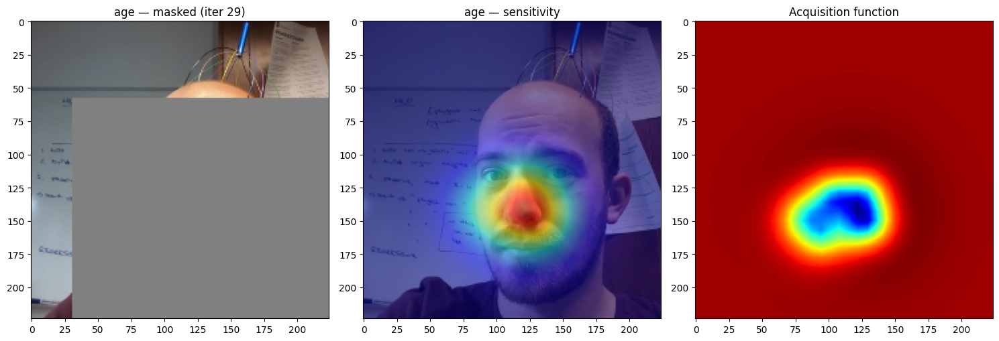

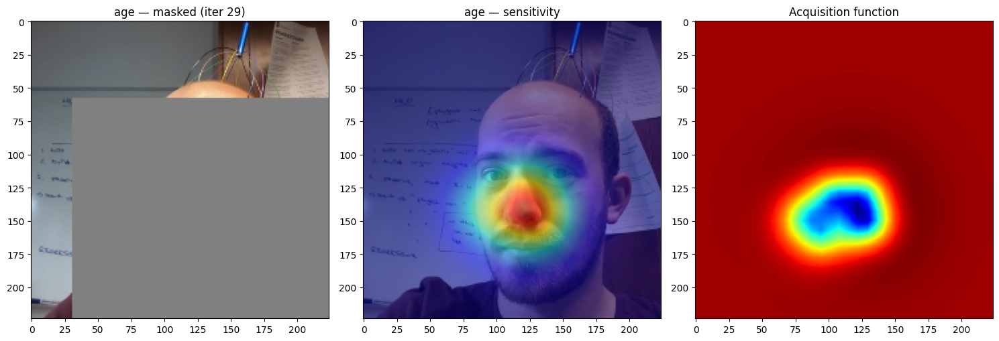


--- FINAL DEBUG SUMMARY ---
Xm sample ranges (first 10):
 [[13.         22.         13.         11.5       ]
 [13.07494744 22.39899045 13.51276248 11.53375001]
 [12.20218546 21.27144617 12.39296918 11.25364891]
 [13.86191308 20.60570117 12.82840265 11.27831969]
 [12.68598586 20.19685514 12.90323234 11.23549046]
 [11.40993019 20.87706775 13.11246194 11.550943  ]
 [11.66163091 20.41862046 13.44209685 11.51377063]
 [15.05153827 18.53195859 13.37425966 11.66241794]
 [14.07801348 18.9263908  12.31039438 12.09989696]
 [14.26124026 18.72130416 12.94827784 11.74569565]]
fm_dict lengths per feature:
Image_Demo_age_Speculation 30  mean: 40.85
mu mean/std: 1.1444084489115527 3.5610455838887165
sig mean/std: 0.9935211670534824 0.035961473640267506
masked speculation mean/std: 80.85 12.8563538117669
age                                                          len= 30 mean=40.850000 std=12.856354


In [16]:
# Pick one feature to test
test_feature = [d for d in demo_features if "age" in d["title"].lower()][0]

# Run the saliency loop for that single feature
run_saliency_for_feature(test_feature, img, baseline_scores)


In [42]:
def run_saliency_for_feature(demo_feature, img, baseline_scores, n_iter=30):
    feature_name = demo_feature["title"].replace(" ", "_")
    feature_key = f"Image_Demo_{feature_name}_Speculation"

    fm_dict = {feature_key: []}  # store raw delta scores
    raw_scores = []

    # Initialize state
    state = X[np.random.randint(0, X.shape[0]), :].astype(float)
    Xm = [state]

    nx, ny, nw, nh = len(np.unique(xv)), len(np.unique(yv)), len(np.unique(wv)), len(np.unique(hv))
    h_img, w_img = img.shape[:2]
    scale_x = w_img / grid_pos
    scale_y = h_img / grid_pos

    for i in range(n_iter):
        try:
            # --- 1. Apply occlusion mask ---
            x0, y0, ww, hh = [float(v) for v in state]
            x0_px = int(round(x0 * scale_x))
            y0_px = int(round(y0 * scale_y))
            ww_px = int(round(ww * scale_x))
            hh_px = int(round(hh * scale_y))

            x1 = max(x0_px - ww_px, 0)
            y1 = max(y0_px - hh_px, 0)
            x2 = min(x0_px + ww_px, w_img)
            y2 = min(y0_px + hh_px, h_img)

            masked_img = img.copy()
            masked_img[y1:y2, x1:x2, :] = 128  # gray patch

            tmp_fd, tmp_path = tempfile.mkstemp(suffix=".jpg")
            os.close(tmp_fd)
            cv2.imwrite(tmp_path, cv2.cvtColor(masked_img, cv2.COLOR_RGB2BGR))

            # --- 2. Query VLM ---
            n_repeat = 1
            masked_scores = []
            for _ in range(n_repeat):
                _, _, masked_result = infer_image_demographics_with_retry(
                    image_source=tmp_path,
                    model_name="Llama-4-Maverick-17B-128E-Instruct-FP8",
                    demo_features=[demo_feature],
                    prefix="Image_Demo",
                )
                ms = masked_result.get(feature_key)
                if ms is not None:
                    masked_scores.append(float(ms))

            try:
                os.remove(tmp_path)
            except:
                pass

            if len(masked_scores) == 0:
                continue
            masked_score = np.mean(masked_scores)
            raw_scores.append(masked_score)

            # --- 3. Compute raw delta  ---
            base_score = baseline_scores.get(feature_key)
            if base_score is None:
                continue
            delta_raw = masked_score - base_score
            fm_dict[feature_key].append(delta_raw)  # store raw difference

            # --- 4. Fit GP ---
            Xm_arr = np.array(Xm)
            gp = GaussianProcessRegressor(kernel=Matern(nu=1.5), alpha=0.05)
            gp.fit(Xm_arr, np.array(fm_dict[feature_key]))

            mu, sig = gp.predict(X, return_std=True)

            # --- 5. Acquisition ---
            aq_bin = int(np.argmax(mu + 1.5 * sig))

            # --- 6. Update next state ---
            state = X[aq_bin].astype(float)
            # add jitter
            state += np.random.randn(4) * [1, 1, 0.5, 0.5]
            # clip to valid ranges
            state = np.clip(state, X.min(axis=0), X.max(axis=0))
            Xm.append(state)

            # --- 7. Visualization ---
            ov = mu.reshape(nx, ny, nw, nh).mean(axis=(-1, -2))
            ov_img = cv2.resize(ov.T.astype(np.float32), (w_img, h_img), interpolation=cv2.INTER_LINEAR)

            fig, ax = plt.subplots(1, 3, figsize=(15, 5))
            ax[0].imshow(masked_img)
            ax[0].set_title(f"{feature_name} — masked (iter {i})")
            ax[1].imshow(img)
            ax[1].imshow(ov_img, alpha=0.5, cmap="jet")
            ax[1].set_title(f"{feature_name} — sensitivity")
            sxy = np.sum(sig.reshape(nx, ny, nw, nh), axis=(-1, -2))
            acq_img = cv2.resize((5 * sxy.T + ov.T).astype(np.float32), (w_img, h_img))
            ax[2].imshow(acq_img, cmap="jet")
            ax[2].set_title("Acquisition function")
            plt.tight_layout()
            display.clear_output(wait=True)
            display.display(plt.gcf())
            plt.pause(0.1)
            plt.close(fig)

        except Exception as e:
            L(f"{feature_name} ITER {i} exception:\n{traceback.format_exc()}")
            break

    # --- 8. Final debug summary ---
    print("\n--- FINAL DEBUG SUMMARY ---")
    print("Xm sample ranges (first 10):\n", np.array(Xm[:10]))
    print("fm_dict lengths per feature:")
    for k, v in fm_dict.items():
        print(k, len(v), " mean:", np.mean(v))
    print("mu mean/std:", mu.mean(), mu.std())
    print("sig mean/std:", sig.mean(), sig.std())
    print("masked speculation mean/std:", np.mean(raw_scores), np.std(raw_scores))

    arr = np.array(fm_dict[feature_key])
    print(f"{feature_name:60s} len={len(arr):3d} mean={arr.mean():.6f} std={arr.std():.6f}")


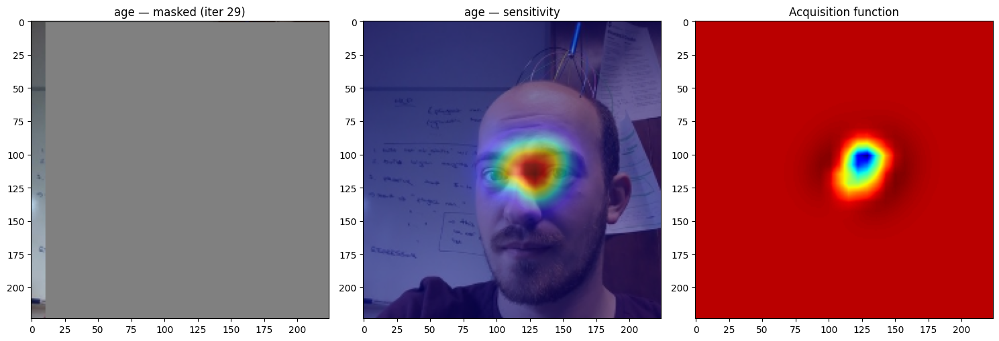

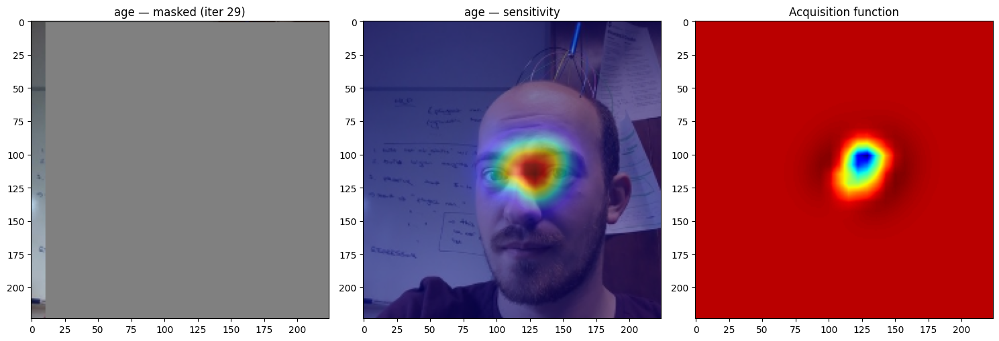


--- FINAL DEBUG SUMMARY ---
Xm sample ranges (first 10):
 [[18.         14.         14.5        13.        ]
 [17.02423136 14.89874655 14.66376807 13.90694273]
 [16.99062655 14.26407275 15.56260347 14.5048646 ]
 [18.46701996 14.14294463 16.         15.49304243]
 [17.57567541 14.95484959 16.         15.39595689]
 [16.96348544 15.88486981 15.67809355 16.        ]
 [17.20510282 13.65871506 16.         16.        ]
 [17.11500088 17.09792829 16.         16.        ]
 [16.75557658 15.8649158  15.89715044 16.        ]
 [17.9998218  15.88329695 16.         16.        ]]
fm_dict lengths per feature:
Image_Demo_age_Speculation 30  mean: 51.75
mu mean/std: 0.1333722119326542 1.5024806520654814
sig mean/std: 0.9994283713612795 0.012610164004200548
masked speculation mean/std: 91.75 13.309614319480987
age                                                          len= 30 mean=51.750000 std=13.309614


In [22]:
test_feature = [d for d in demo_features if "age" in d["title"].lower()][0]
run_saliency_for_feature(test_feature, img, baseline_scores)


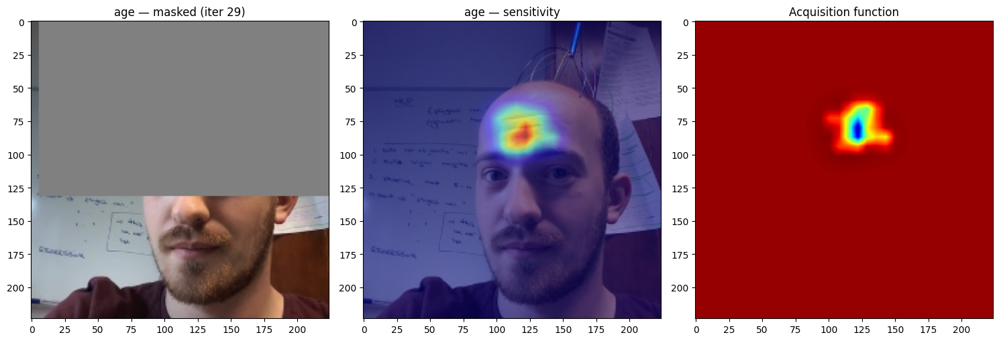

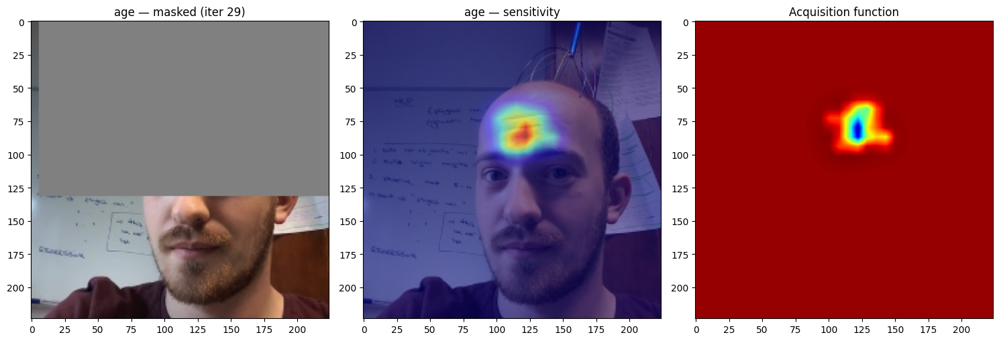


--- FINAL DEBUG SUMMARY ---
Xm sample ranges (first 10):
 [[17.         11.         16.         10.        ]
 [16.95965261 11.45433784 15.55549199  9.90370578]
 [16.10796334 11.0458416  15.36550204 10.03445349]
 [16.76134847 12.32716698 16.          9.99916399]
 [16.50325705  9.92967268 16.         10.07050963]
 [16.73412253 12.12755553 14.98802957 10.07827788]
 [16.76201261 11.72055021 15.01248804  9.74964402]
 [17.66055706 10.64521718 15.33889516 10.01446916]
 [18.38645241  9.59117666 16.          9.93427741]
 [17.39703272 12.12186255 15.36844613  9.92633273]]
fm_dict lengths per feature:
Image_Demo_age_Speculation 30  mean: 19.333333333333332
mu mean/std: 0.01873294045691385 0.350881610069348
sig mean/std: 0.9998634778843606 0.005670214277974689
masked speculation mean/std: 59.333333333333336 7.272474743090475
age                                                          len= 30 mean=19.333333 std=7.272475


In [ ]:
# sig coe=5
test_feature = [d for d in demo_features if "age" in d["title"].lower()][0]
run_saliency_for_feature(test_feature, img, baseline_scores)


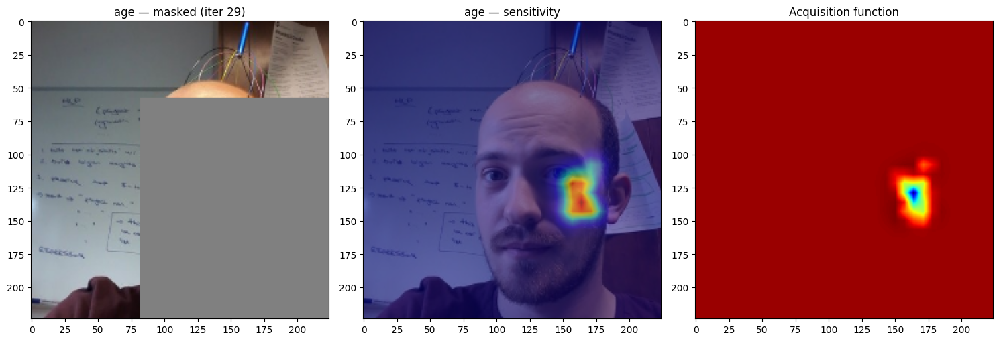

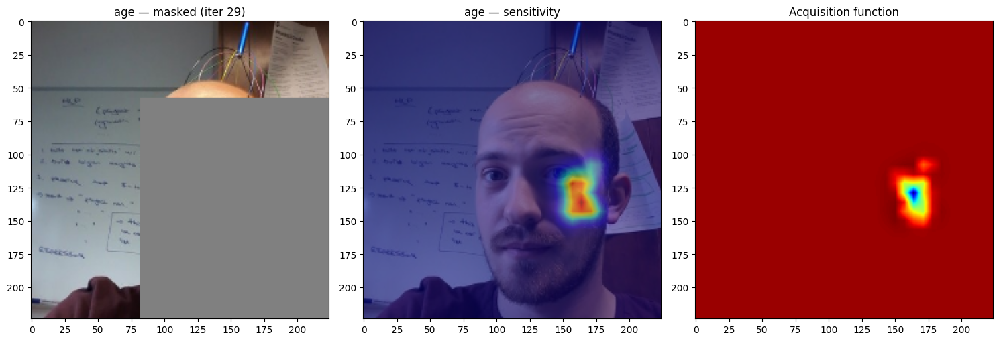


--- FINAL DEBUG SUMMARY ---
Xm sample ranges (first 10):
 [[23.         18.         10.         11.5       ]
 [22.6160731  16.99133741  8.87349947 11.98581555]
 [22.6638035  17.32908825  9.38137818 11.95656282]
 [22.25956653 17.15706513 10.36906788 11.02584476]
 [23.28202748 16.84347784 10.56723997 11.85040073]
 [22.58270149 17.78431962  8.61416705 12.06125833]
 [23.68774183 18.38774431  9.27885609 11.53911017]
 [24.35082277 15.10539404  9.90621285 10.42132292]
 [21.4783587  16.50191045  9.74503321 11.79415439]
 [22.03768002 17.15313127  9.34372621 10.37208285]]
fm_dict lengths per feature:
Image_Demo_age_Speculation 30  mean: 21.333333333333332
mu mean/std: 0.017171094648924166 0.37962819336674614
sig mean/std: 0.999894358368647 0.005227835383099942
masked speculation mean/std: 61.333333333333336 13.84035966135113
age                                                          len= 30 mean=21.333333 std=13.840360


In [46]:
test_feature = [d for d in demo_features if "age" in d["title"].lower()][0]
run_saliency_for_feature(test_feature, img, baseline_scores)


# New attempt 3/11

In [14]:
def run_saliency_for_feature(demo_feature, img, baseline_scores, n_iter=200):
    feature_name = demo_feature["title"].replace(" ", "_")
    feature_key = f"Image_Demo_{feature_name}_Speculation"

    fm_dict = {feature_key: []}  # store raw delta scores
    raw_scores = []

    # Initialize state
    state = X[np.random.randint(0, X.shape[0]), :].astype(float)
    Xm = [state]

    nx, ny, nw, nh = len(np.unique(xv)), len(np.unique(yv)), len(np.unique(wv)), len(np.unique(hv))
    h_img, w_img = img.shape[:2]
    scale_x = w_img / grid_pos
    scale_y = h_img / grid_pos

    n_initial = 10  # number of random samples before GP optimization

    for i in range(n_iter):
        try:
            # --- 1. Apply occlusion mask ---
            x0, y0, ww, hh = [float(v) for v in state]
            x0_px = int(round(x0 * scale_x))
            y0_px = int(round(y0 * scale_y))
            ww_px = int(round(ww * scale_x))
            hh_px = int(round(hh * scale_y))

            x1 = max(x0_px - ww_px, 0)
            y1 = max(y0_px - hh_px, 0)
            x2 = min(x0_px + ww_px, w_img)
            y2 = min(y0_px + hh_px, h_img)

            masked_img = img.copy()
            masked_img[y1:y2, x1:x2, :] = 128

            tmp_fd, tmp_path = tempfile.mkstemp(suffix=".jpg")
            os.close(tmp_fd)
            cv2.imwrite(tmp_path, cv2.cvtColor(masked_img, cv2.COLOR_RGB2BGR))

            # --- 2. Query VLM ---
            n_repeat = 1
            masked_scores = []
            for _ in range(n_repeat):
                _, _, masked_result = infer_image_demographics_with_retry(
                    image_source=tmp_path,
                    model_name="Llama-4-Maverick-17B-128E-Instruct-FP8",
                    demo_features=[demo_feature],
                    prefix="Image_Demo",
                )
                ms = masked_result.get(feature_key)
                if ms is not None:
                    masked_scores.append(float(ms))

            try:
                os.remove(tmp_path)
            except:
                pass

            if len(masked_scores) == 0:
                continue
            masked_score = np.mean(masked_scores)
            raw_scores.append(masked_score)

            # --- 3. Compute raw delta ---
            base_score = baseline_scores.get(feature_key)
            if base_score is None:
                continue
            delta_raw = masked_score - base_score
            fm_dict[feature_key].append(delta_raw)

            # --- 4. Choose next state ---
            if i < n_initial - 1:
                # Random exploration for initial samples
                state = X[np.random.randint(0, X.shape[0]), :].astype(float)
            else:
                # GP optimization after collecting initial samples
                Xm_arr = np.array(Xm)
                gp = GaussianProcessRegressor(kernel=Matern(nu=1.5), alpha=0.05)
                gp.fit(Xm_arr, np.array(fm_dict[feature_key]))

                mu, sig = gp.predict(X, return_std=True)

                # --- 5. Acquisition ---
                aq_bin = int(np.argmax(mu + 1.5 * sig))

                # --- 6. Update next state ---
                state = X[aq_bin].astype(float)
            
            # add jitter
            state += np.random.randn(4) * [1, 1, 0.5, 0.5]
            state = np.clip(state, X.min(axis=0), X.max(axis=0))
            Xm.append(state)

            # --- 7. Visualization (only if GP has been fit) ---
            if i >= n_initial - 1:
                ov = mu.reshape(nx, ny, nw, nh).mean(axis=(-1, -2))
                ov_img = cv2.resize(ov.T.astype(np.float32), (w_img, h_img), interpolation=cv2.INTER_LINEAR)

                fig, ax = plt.subplots(1, 3, figsize=(15, 5))
                ax[0].imshow(masked_img)
                ax[0].set_title(f"{feature_name} — masked (iter {i})")
                ax[1].imshow(img)
                ax[1].imshow(ov_img, alpha=0.5, cmap="jet")
                ax[1].set_title(f"{feature_name} — sensitivity")
                sxy = np.sum(sig.reshape(nx, ny, nw, nh), axis=(-1, -2))
                acq_img = cv2.resize((5 * sxy.T + ov.T).astype(np.float32), (w_img, h_img))
                ax[2].imshow(acq_img, cmap="jet")
                ax[2].set_title("Acquisition function")
                plt.tight_layout()
                display.clear_output(wait=True)
                display.display(plt.gcf())
                plt.pause(0.1)
                plt.close(fig)
        except Exception as e:
            L(f"{feature_name} ITER {i} exception:\n{traceback.format_exc()}")
            break

    # --- 8. Final debug summary ---
    print("\n--- FINAL DEBUG SUMMARY ---")
    print("Xm sample ranges (first 10):\n", np.array(Xm[:10]))
    print("fm_dict lengths per feature:")
    for k, v in fm_dict.items():
        print(k, len(v), " mean:", np.mean(v))
    print("mu mean/std:", mu.mean(), mu.std())
    print("sig mean/std:", sig.mean(), sig.std())
    print("masked speculation mean/std:", np.mean(raw_scores), np.std(raw_scores))

    arr = np.array(fm_dict[feature_key])
    print(f"{feature_name:60s} len={len(arr):3d} mean={arr.mean():.6f} std={arr.std():.6f}")

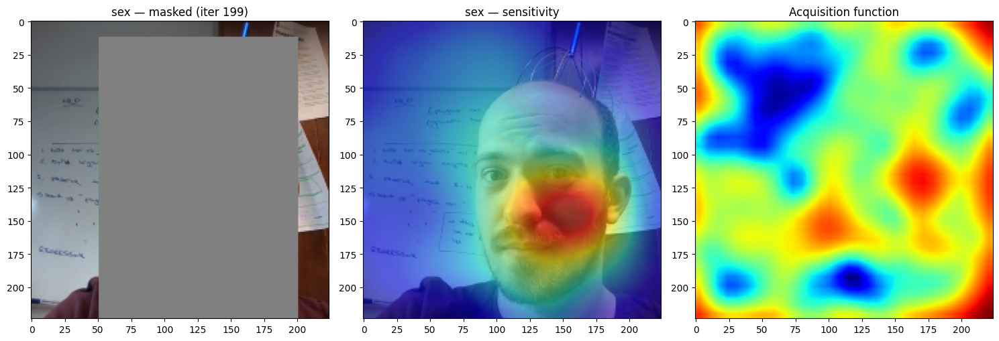

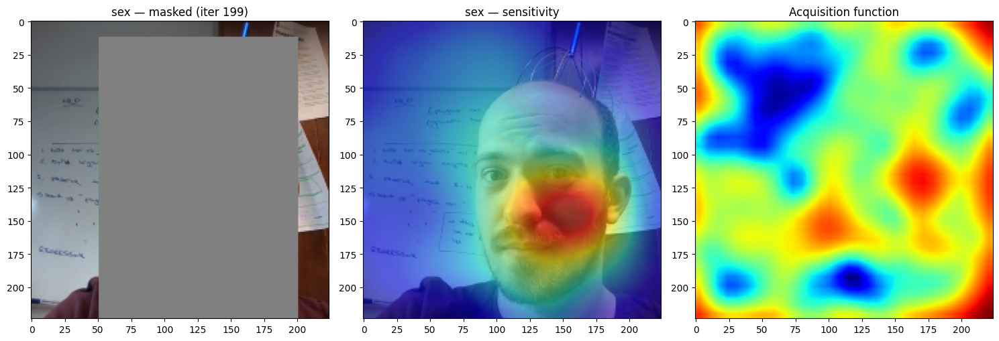


--- FINAL DEBUG SUMMARY ---
Xm sample ranges (first 10):
 [[18.         28.         10.         16.        ]
 [12.28324674  1.128825    7.04006197 15.1501757 ]
 [ 7.11068795 12.93933515 11.03774843  8.94427015]
 [11.36691338  6.82389557  5.04485108  4.36170805]
 [10.04873295 15.9323765   6.64294494  8.39097818]
 [ 1.38407311 24.62498731 15.52114628 13.16184033]
 [25.31858115 20.64827153 13.1152925  10.38856959]
 [27.84330105 18.21586708  7.28976064 14.92168039]
 [ 9.09718791  8.23485949  4.55816823 12.2726103 ]
 [26.24787108 21.12054177 14.32951866  9.14987331]]
fm_dict lengths per feature:
Image_Demo_sex_Speculation 200  mean: 59.4
mu mean/std: 15.880165488471013 13.238131999712948
sig mean/std: 0.8269583833576581 0.11709272359889224
masked speculation mean/std: 59.4 40.13277961965755
sex                                                          len=200 mean=59.400000 std=40.132780


In [39]:
test_feature = [d for d in demo_features if "sex" in d["title"].lower()][0]
run_saliency_for_feature(test_feature, img, baseline_scores)


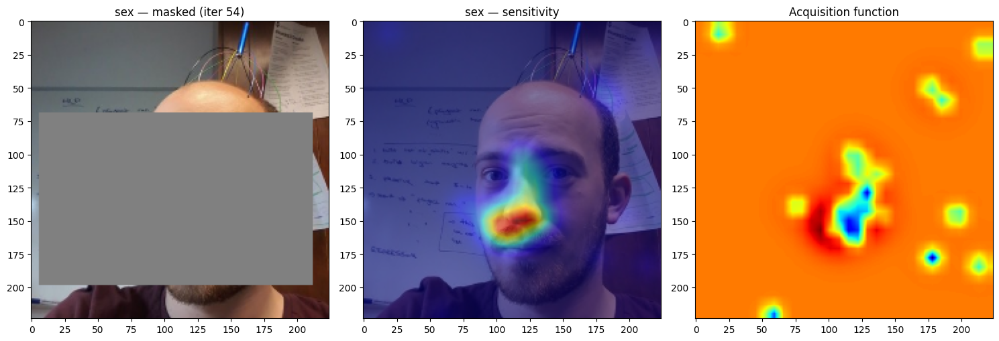

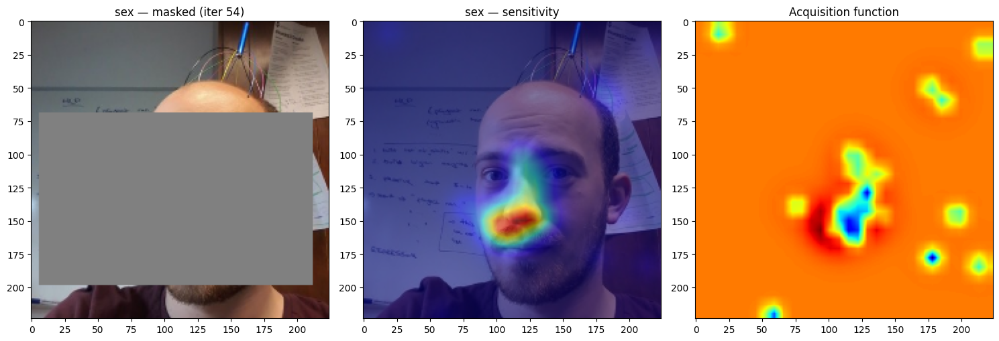

KeyboardInterrupt: 

In [15]:
test_feature = [d for d in demo_features if "sex" in d["title"].lower()][0]
run_saliency_for_feature(test_feature, img, baseline_scores)


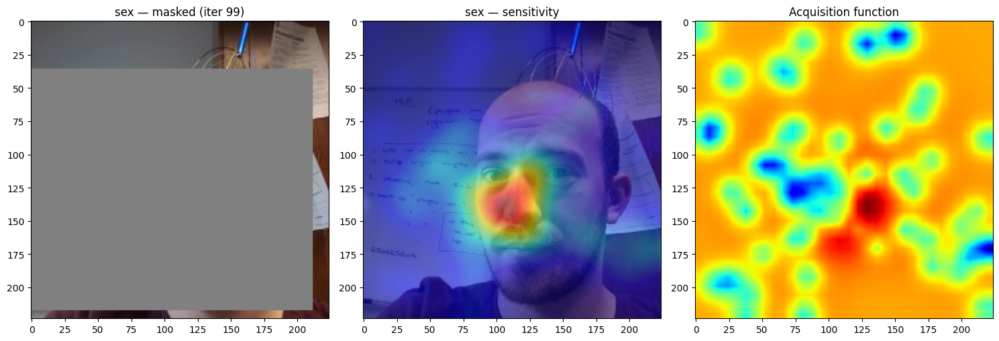

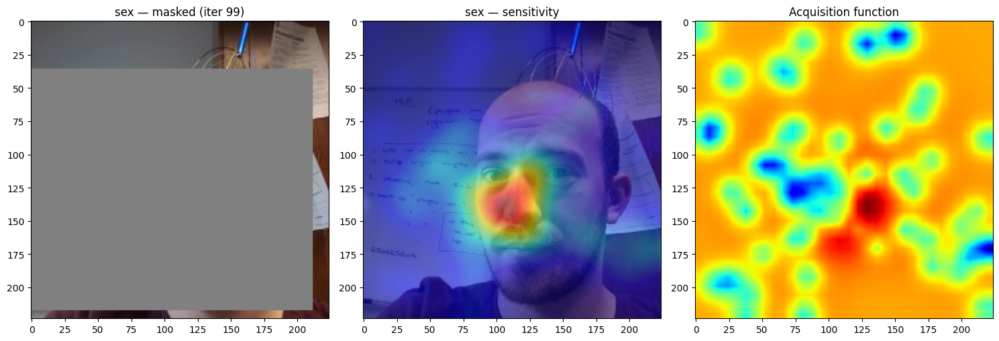


--- FINAL DEBUG SUMMARY ---
Xm sample ranges (first 10):
 [[ 5.         20.         10.         10.        ]
 [ 9.79155294  5.60377421  7.0604734   4.02443429]
 [11.33754947  1.77189978  6.55447103 11.45020226]
 [ 3.39351582  5.6923782   6.16587891  8.5321144 ]
 [27.8055893  26.64155453 10.66999763  4.        ]
 [11.46181582 22.4765752  16.          8.35659366]
 [11.31089944 31.          8.50426369 11.2070219 ]
 [20.09131042 11.16614563 13.26917886 10.13680758]
 [ 7.5924789  14.97657228  4.          8.27578867]
 [ 6.80328039 24.54321055  4.         16.        ]]
fm_dict lengths per feature:
Image_Demo_sex_Speculation 100  mean: 50.71
mu mean/std: 2.02099348723982 4.869813448585033
sig mean/std: 0.9914603575001321 0.03226591317240905
masked speculation mean/std: 50.71 37.77705520550801
sex                                                          len=100 mean=50.710000 std=37.777055


In [30]:
test_feature = [d for d in demo_features if "sex" in d["title"].lower()][0]
run_saliency_for_feature(test_feature, img, baseline_scores)


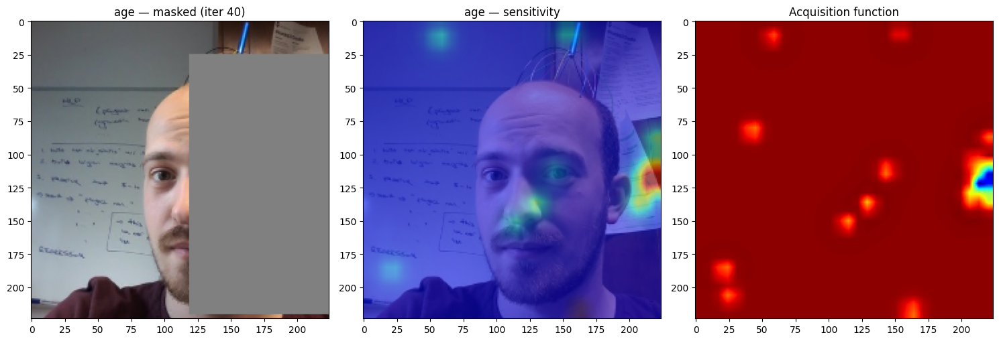

KeyboardInterrupt: 

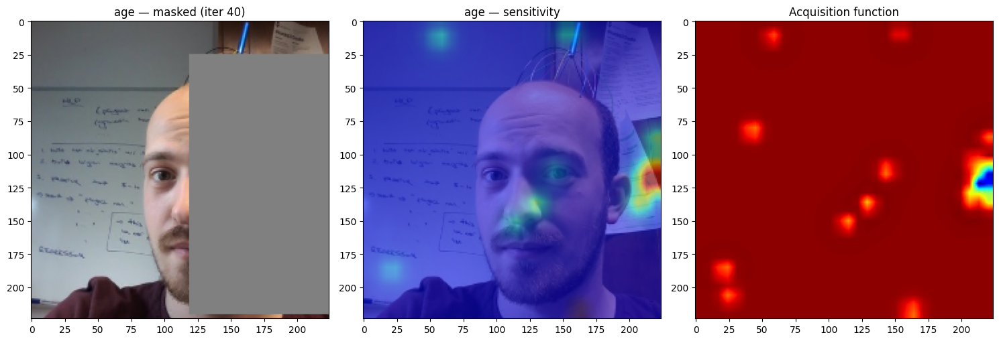

In [16]:
test_feature = [d for d in demo_features if "age" in d["title"].lower()][0]
run_saliency_for_feature(test_feature, img, baseline_scores)


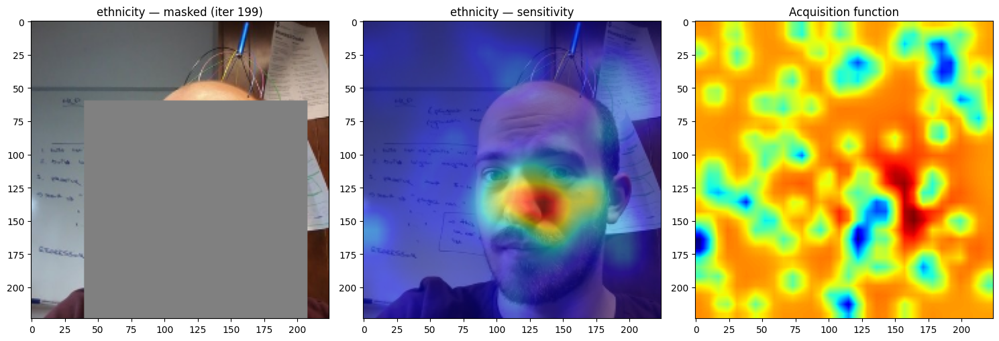

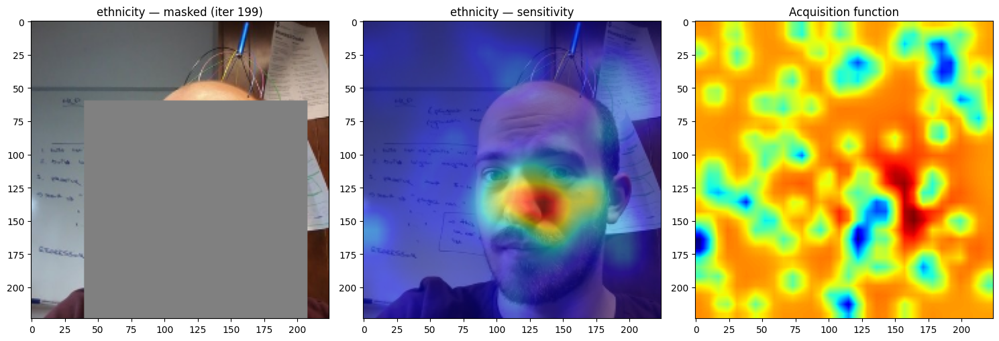


--- FINAL DEBUG SUMMARY ---
Xm sample ranges (first 10):
 [[11.         14.         14.5         7.        ]
 [13.17648826 19.73043708  8.52631929  7.65040287]
 [10.51938697 19.30000078 11.18897744  4.33460841]
 [ 2.62047238 29.96787131 11.87876459 12.7367901 ]
 [10.31188237 13.57268393 14.96668849  4.00269735]
 [28.16049371  1.17789463  4.57569715  4.65112711]
 [ 1.58857618  7.38148501  4.60329788  8.72207462]
 [28.33247229  8.09898333 15.69298018 14.57920273]
 [15.12175491  6.53298452  9.77474451 15.48605357]
 [25.62707566 11.40468076  6.5793841  14.58596923]]
fm_dict lengths per feature:
Image_Demo_ethnicity_Speculation 200  mean: 46.2
mu mean/std: 2.215062047188622 4.415595073744757
sig mean/std: 0.9913483134486151 0.032338170451799104
masked speculation mean/std: 66.2 29.454371492191108
ethnicity                                                    len=200 mean=46.200000 std=29.454371


In [35]:
test_feature = [d for d in demo_features if "ethnicity" in d["title"].lower()][0]
run_saliency_for_feature(test_feature, img, baseline_scores)


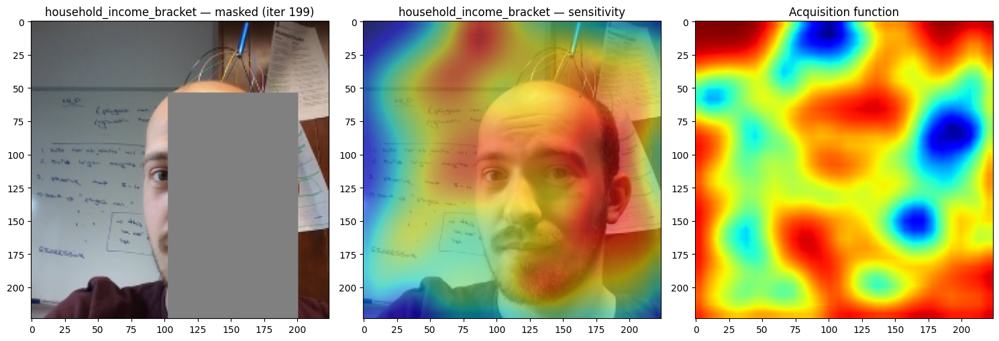

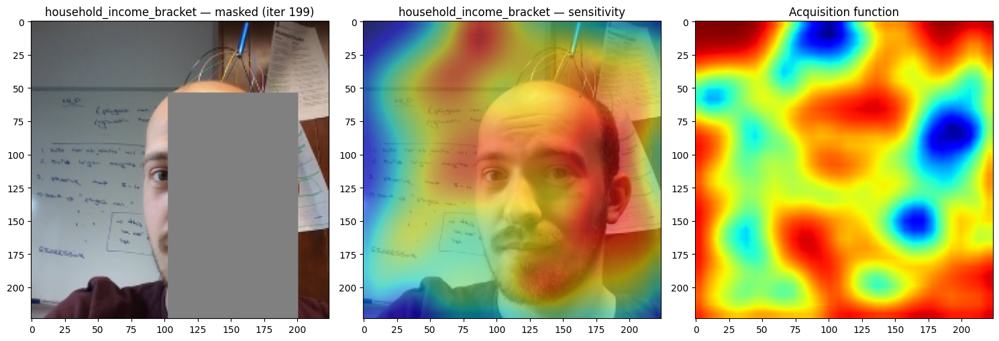


--- FINAL DEBUG SUMMARY ---
Xm sample ranges (first 10):
 [[ 8.         29.         11.5        10.        ]
 [16.15074885 12.6620383  12.90019523 15.01291426]
 [16.77898157 26.20159198  4.11042782  4.        ]
 [21.21949846  5.74984123  9.98553476 13.94967934]
 [14.86028639  0.20961157 15.21250262 15.02057107]
 [ 5.21345306 21.37302483  7.60995023 14.1907422 ]
 [ 4.73944295 15.6803861   8.46582287  9.89344705]
 [ 2.43715542 23.47054024 11.57374289 15.57563965]
 [13.26228215 11.65680549  9.14866132  8.19737779]
 [14.14936102  0.         11.40745188  5.34865039]]
fm_dict lengths per feature:
Image_Demo_household_income_bracket_Speculation 200  mean: 23.91
mu mean/std: 12.691013006778954 5.634890993195805
sig mean/std: 0.8888248175380214 0.10461258581216412
masked speculation mean/std: 83.91 7.531394293223533
household_income_bracket                                     len=200 mean=23.910000 std=7.531394


In [38]:
test_feature = [d for d in demo_features if "household income bracket" in d["title"].lower()][0]
run_saliency_for_feature(test_feature, img, baseline_scores)


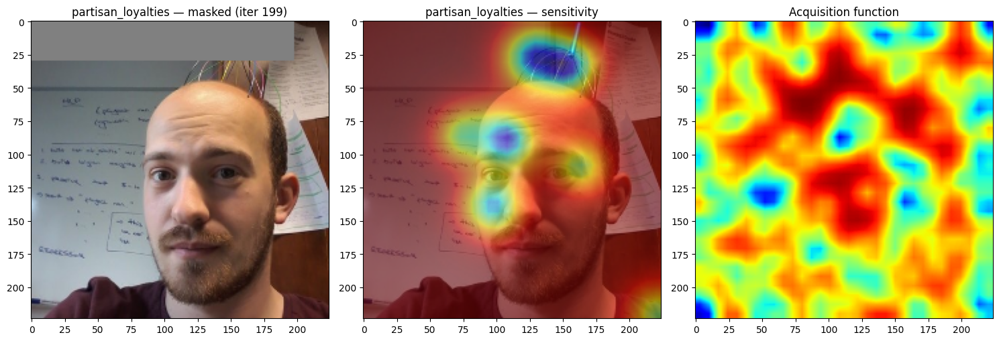

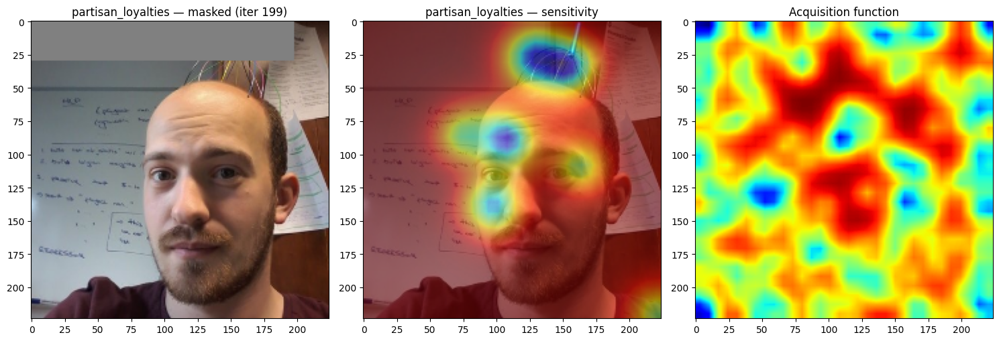


--- FINAL DEBUG SUMMARY ---
Xm sample ranges (first 10):
 [[13.         22.          7.         16.        ]
 [18.74108923 28.84100101  7.93225161 11.26730321]
 [22.5699184  18.4613563  12.75804415  6.93971756]
 [ 5.76488683 17.83073214  6.28652857  9.11775266]
 [ 0.         15.18718094 15.86261307 16.        ]
 [ 8.64981128 17.18771792  4.69359625  6.42414963]
 [ 1.92434517 20.99898356 11.63842887 11.48203308]
 [10.09867475 20.4400278  13.21681214 13.50421937]
 [24.09115891 31.          8.79939942 16.        ]
 [17.68886143  9.71785726 15.55315935 14.38586472]]
fm_dict lengths per feature:
Image_Demo_partisan_loyalties_Speculation 200  mean: -0.35
mu mean/std: -0.11099962950466476 0.4180385841305812
sig mean/std: 0.9718107444499897 0.05053109509333752
masked speculation mean/std: 99.65 1.837797594948911
partisan_loyalties                                           len=200 mean=-0.350000 std=1.837798


In [37]:
test_feature = [d for d in demo_features if "partisan loyalties" in d["title"].lower()][0]
run_saliency_for_feature(test_feature, img, baseline_scores)
